## 1. Титульный лист
# Предобработка данных и регрессия на датасете «House Prices»
**Модуль 2. Лабораторная работа 2**  
**Дисциплина:** Машинное обучение и искусственный интеллект  
**Выполнил:** Федорушкин Станислав, **ПКТб-23-1**  
**Дата выполнения:** 27.10.2026  
**Репозиторий:** https://github.com/Ogn1k/ml-course-fedorushkin  
**Путь:** `module-2-house-prices/notebook.ipynb`  
**Датасет:** House Prices — Advanced Regression Techniques.

Работа подготовлена с помощью OpenAI Codex: анализ методички, разработка кода и оформление отчёта.
Результаты ниже получены исполнением кода, а не перенесены из примеров методички.

## 2. Введение
Предсказываем цену продажи дома в долларах по его характеристикам. Это регрессия:
ответ — число, тогда как классификация выбирает класс, например «дорогой/дешёвый».
ML-проект включает изучение исходных данных, построение преобразований, обучение,
независимую проверку и сохранение воспроизводимого способа предсказания.

Цели: провести EDA; сравнить Linear Regression, Ridge, Lasso и ElasticNet
с ориентиром R² ≥ 0.90; реализовать предсказание для нового дома.
Основная метрика выбора — RMSE(log1p цены), согласованная с относительной ошибкой.
MAE в долларах объясняет средний абсолютный промах, RMSE в долларах выделяет крупные
ошибки, R² показывает долю объяснённой дисперсии. Обе шкалы R² подписаны отдельно.

## 3. Теоретическая часть
**Регрессия.** Модель связывает признаки объекта с числовым ответом.
Линейная модель имеет вид $\hat z=b+\sum_j w_jx_j$.
Коэффициенты находят минимизацией ошибки на известных продажах.
В отличие от классификации, нет конечного списка классов ответа.
Примеры — прогноз цены, температуры и длительности поездки.

**Пропуски.** Значение может отсутствовать из-за сбоя измерения или отсутствия объекта.
MCAR означает независимость пропуска от наблюдаемых и ненаблюдаемых данных.
При MAR пропуск объясняется наблюдаемыми признаками, при MNAR зависит и от неизвестного значения.
По одной таблице нельзя достоверно установить механизм пропуска.
Для отсутствующего гаража уместен ноль площади, для неизвестного фасада — медиана района,
изученная только на обучении; остальные числовые значения заполняются медианой, категории модой.

**Регуляризация.** Большое количество связанных признаков делает оценки OLS нестабильными.
Ridge добавляет штраф L2 и уменьшает коэффициенты.
Lasso использует L1 и способен обнулить часть весов.
ElasticNet сочетает оба штрафа, что полезно при связанных площадях и характеристиках гаража.
Масштабирование нужно для сопоставимого штрафа числовых признаков.
Силу штрафа выбираем по пяти фолдам, а не по отложенным ответам.

| Модель | Штраф | Особенность |
|---|---|---|
| OLS | 0 | Базовая линейная модель |
| Ridge | $\alpha\|w\|_2^2$ | Стабилизация связанных признаков |
| Lasso | $\alpha\|w\|_1$ | Разреженные коэффициенты |
| ElasticNet | $\alpha\rho\|w\|_1+\alpha(1-\rho)\|w\|_2^2/2$ | Сочетание L1/L2 |

**Логарифмирование.** Дорогие дома образуют правый хвост распределения.
$z=\log(1+y)$ сжимает этот хвост, а $y=\exp(z)-1$ возвращает доллары.
Квадрат ошибки в логарифмах сильнее связан с относительной, чем с абсолютной ошибкой цены.
Нормальность целевой не является обязательным условием линейной регрессии;
логарифмирование также не гарантирует нормальных остатков или постоянства их дисперсии.

**Feature Engineering.** Сумма площадей описывает размер всего дома.
Возраст на момент продажи удобнее абсолютного календарного года.
Индикаторы наличия гаража и камина отделяют отсутствие объекта от его размера.
Взаимодействие качества и площади позволяет цене площади зависеть от качества дома.

**Метрики.** MSE — средний квадрат ошибки, измеряется в квадрате единиц цели.
RMSE извлекает корень и возвращает исходную размерность.
MAE — среднее абсолютное отклонение, это не медиана ошибки.
R² сравнивает сумму квадратов ошибок с прогнозом среднего фактической выборки.
Отрицательный R² возможен у модели хуже этого прогноза.
Нужно различать метрики для $y$ в долларах и для $z=\log(1+y)$:
$$MSE=\frac1n\sum_i(y_i-\hat y_i)^2,\qquad RMSE=\sqrt{MSE}$$
$$MAE=\frac1n\sum_i|y_i-\hat y_i|,\qquad
R^2=1-\frac{\sum_i(y_i-\hat y_i)^2}{\sum_i(y_i-\bar y)^2}.$$

**Кросс-валидация.** KFold делит обучение на пять частей: каждую по очереди проверяют
на модели, обученной на четырёх остальных. GridSearchCV выбирает параметры с наименьшим
средним RMSE(log). Импутация, кодирование и масштабирование повторно обучаются внутри
каждого фолда через Pipeline. После выбора остаётся одна независимая проверка holdout.

## 4. Описание данных
Источник: [Kaggle House Prices](https://www.kaggle.com/c/house-prices-advanced-regression-techniques).
Данные продаж в Эймсе, штат Айова, за 2006–2010 годы происходят из Ames Housing Дина Де Кока.
Исходный Ames содержит 2930 наблюдений; соревновательная версия — 1460 train и 1459 test.
В train 81 столбец: 79 признаков, Id и SalePrice; в test нет SalePrice.
Числовых признаков по dtype — 36, строковых — 43; порядковые шкалы выделяются по смыслу.

| Признак | Описание | Единицы |
|---|---|---|
| SalePrice | Цена продажи, цель | USD |
| OverallQual | Общее качество | 1–10 |
| GrLivArea | Надземная жилая площадь | кв. футы |
| TotalBsmtSF | Площадь подвала | кв. футы |
| YearBuilt | Год постройки | год |
| Neighborhood | Район | категория |
| LotFrontage | Длина фасада участка вдоль улицы | футы |

Словарь всех признаков: `data/data_description.txt`; происхождение и SHA-256:
`data/provenance.json`. Использовано зеркало CSV, а не чужой готовый notebook.

In [1]:
# Импортируем библиотеки и ограничиваем BLAS для воспроизводимого времени.
import os
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['OPENBLAS_NUM_THREADS'] = '1'
from pathlib import Path
import json
import time
import platform
import warnings
import hashlib
import importlib.metadata as md
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display, Markdown
from scipy import stats
from threadpoolctl import threadpool_limits
from sklearn.base import clone
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from housing_pipeline import make_pipeline, predict_price, load_remote_model

# Новые категории ожидаемы внутри CV: ignore кодирует их нулями.
# Скрываем только повторяющееся уведомление энкодера, остальные предупреждения видны.
warnings.filterwarnings('ignore', message='Found unknown categories in columns.*',
                        category=UserWarning, module=r'sklearn\.preprocessing\._encoders')
# Запускаем notebook из каталога модуля; все файлы имеют относительные пути.
assert Path('housing_pipeline.py').exists(), 'Запускайте из module-2-house-prices'
for folder in ['models', 'examples']:
    Path(folder).mkdir(exist_ok=True)
sns.set_theme(style='whitegrid', font='DejaVu Sans')
train_df = pd.read_csv('data/train.csv', keep_default_na=False, na_values=['NA', ''])
test_df = pd.read_csv('data/test.csv', keep_default_na=False, na_values=['NA', ''])
print(train_df.shape, test_df.shape)
assert train_df.shape == (1460, 81) and test_df.shape == (1459, 80)
assert train_df.Id.is_unique and test_df.Id.is_unique
assert set(train_df.Id).isdisjoint(test_df.Id)
display(train_df.head())
train_df.info()
display(train_df.describe())
# Статистики считаются по данным: текстовые категории None не теряются при чтении.
display(train_df.SalePrice.describe().to_frame())
print('skew:', train_df.SalePrice.skew(), 'kurtosis:', train_df.SalePrice.kurtosis())
print('Числовых признаков:', train_df.drop(columns=['Id','SalePrice']).select_dtypes('number').shape[1])

(1460, 81) (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


,SalePrice
count,1460.000000
mean,180921.195890
std,79442.502883
min,34900.000000
25%,129975.000000
50%,163000.000000
75%,214000.000000
max,755000.000000


skew: 1.8828757597682129 kurtosis: 6.536281860064529
Числовых признаков: 36


Среднее выше медианы и есть длинный правый хвост. Число NA зависит от правил
чтения CSV: строковое `None` в MasVnrType — допустимое значение, а `NA` — пропуск.
Поэтому статистика пропусков может отличаться от примера, прочитанного с настройками pandas по умолчанию.

## 5. Подготовка данных и EDA
Сначала фиксируем разделение 80/20 с random_state=42. EDA и правила обработки
изучаются на обучающей части; holdout не очищается и не участвует в подборе.
IQR выявляет необычные площади, но большой дорогой дом сам по себе не ошибка.
Удаляем только два известных типа аномальных наблюдений по заранее заданному правилу
GrLivArea > 4000 и SalePrice < 300000, причём исключительно из обучения.

,Пропусков
PoolQC,1162
MiscFeature,1122
Alley,1094
Fence,935
FireplaceQu,547
LotFrontage,217
GarageFinish,64
GarageQual,64
GarageYrBlt,64
GarageType,64


IQR кандидатов: 23 Удаляем по доменному правилу: 2


,Id,GrLivArea,SalePrice
523,524,4676,184750
1298,1299,5642,160000


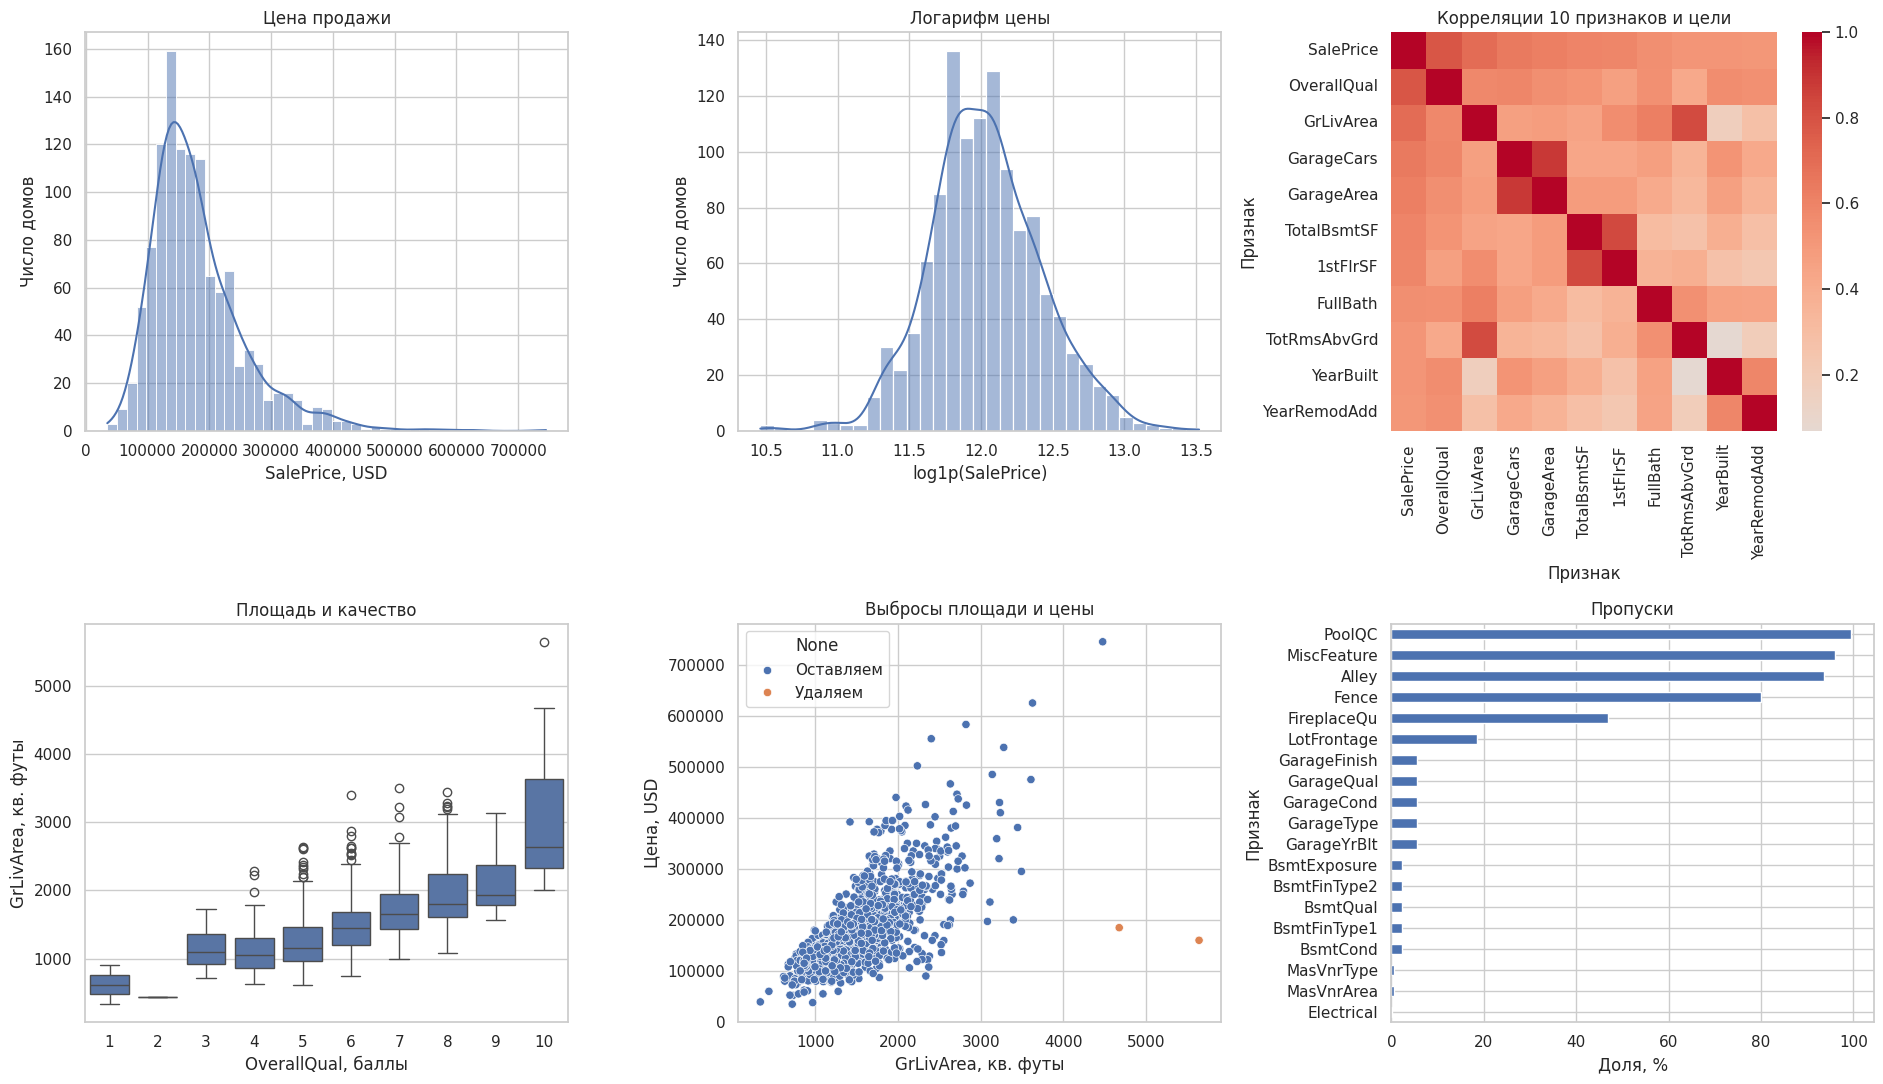

Асимметрия до/после log1p: 1.743128561420854 0.12489024367919244
Корреляция GarageCars/GarageArea: 0.8825495083743983
Размер обучения и holdout: 1166 292


In [2]:
# Отделяем Id и цель; SalePrice_log никогда не входит в признаки.
X = train_df.drop(columns=['Id', 'SalePrice'])
y = np.log1p(train_df.SalePrice)
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=.2, random_state=42)
eda = train_df.loc[X_train.index].copy()
missing = eda.isna().sum().sort_values(ascending=False)
display(missing[missing > 0].to_frame('Пропусков'))
q1, q3 = eda.GrLivArea.quantile([.25, .75])
iqr_mask = (eda.GrLivArea < q1-1.5*(q3-q1)) | (eda.GrLivArea > q3+1.5*(q3-q1))
outlier_mask = (X_train.GrLivArea > 4000) & (np.expm1(y_train) < 300000)
print('IQR кандидатов:', iqr_mask.sum(), 'Удаляем по доменному правилу:', outlier_mask.sum())
display(eda.loc[outlier_mask, ['Id', 'GrLivArea', 'SalePrice']])

# Шесть графиков с отдельными заголовками и подписями осей.
fig, axes = plt.subplots(2, 3, figsize=(19, 11))
sns.histplot(eda.SalePrice, kde=True, ax=axes[0,0])
axes[0,0].set(title='Цена продажи', xlabel='SalePrice, USD', ylabel='Число домов')
sns.histplot(np.log1p(eda.SalePrice), kde=True, ax=axes[0,1])
axes[0,1].set(title='Логарифм цены', xlabel='log1p(SalePrice)', ylabel='Число домов')
top = eda.select_dtypes('number').corr().SalePrice.abs().nlargest(11).index
sns.heatmap(eda[top].corr(), cmap='coolwarm', center=0, ax=axes[0,2])
axes[0,2].set(title='Корреляции 10 признаков и цели', xlabel='Признак', ylabel='Признак')
sns.boxplot(data=eda, x='OverallQual', y='GrLivArea', ax=axes[1,0])
axes[1,0].set(title='Площадь и качество', xlabel='OverallQual, баллы', ylabel='GrLivArea, кв. футы')
sns.scatterplot(data=eda, x='GrLivArea', y='SalePrice', hue=outlier_mask.map({True:'Удаляем',False:'Оставляем'}), ax=axes[1,1])
axes[1,1].set(title='Выбросы площади и цены', xlabel='GrLivArea, кв. футы', ylabel='Цена, USD')
(missing[missing > 0] / len(eda) * 100).sort_values().plot.barh(ax=axes[1,2])
axes[1,2].set(title='Пропуски', xlabel='Доля, %', ylabel='Признак')
fig.tight_layout()
fig.savefig('examples/eda_plots.png', dpi=140)
plt.show()
print('Асимметрия до/после log1p:', eda.SalePrice.skew(), np.log1p(eda.SalePrice).skew())
print('Корреляция GarageCars/GarageArea:', eda.GarageCars.corr(eda.GarageArea))
# Убираем аномалии только из обучения; все 292 holdout-дома сохраняются.
X_train, y_train = X_train.loc[~outlier_mask], y_train.loc[~outlier_mask]
print('Размер обучения и holdout:', len(X_train), len(X_valid))

Гистограммы показывают уменьшение правой асимметрии после log1p.
На scatter видны большие дома с низкой ценой; IQR также отмечает вполне реальные дорогие дома,
поэтому автоматически удалять все IQR-кандидаты не стали. Heatmap показывает связь цены
с качеством и площадями и взаимную корреляцию площадей гаража и его вместимости.
Boxplot показывает разброс площади внутри одного уровня качества.
Большая доля NA в качестве бассейна не повод удалять признак: чаще бассейна просто нет.

`HouseFeatures` заполняет смысловые пропуски None, числовые — нулями при подтверждённом
отсутствии объекта. Неизвестные значения у существующих объектов проходят медианную/модальную
импутацию. LotFrontage заполняется медианой Neighborhood с общей медианой для нового района.
MasVnrType=None сохраняется как категория; неизвестное значение помечается Unknown.
Создаются TotalSF, TotalBath, TotalPorch, HouseAge, RemodAge, GarageAge, пять индикаторов
и OverallQual_TotalSF. Порядковое качество кодируется вручную от None=0 до Ex=5,
номинальные категории — OneHotEncoder. Все обучаемые преобразования находятся внутри Pipeline.

In [3]:
# Показываем, что признаки создаются без изучения holdout и без целевой переменной.
preview_pipeline = make_pipeline(Ridge())
prepared = preview_pipeline[:-1].fit_transform(X_train, y_train)
feature_names = preview_pipeline.named_steps['preprocess'].get_feature_names_out().tolist()
assert np.isfinite(prepared).all()
assert 'SalePrice' not in feature_names and 'Id' not in feature_names
print('После преобразований:', prepared.shape, 'NaN:', np.isnan(prepared).sum())
display(preview_pipeline.named_steps['features'].transform(X_train).head())

После преобразований: (1166, 261) NaN: 0


,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,TotalPorch,HouseAge,RemodAge,GarageAge,HasPool,HasGarage,Has2ndFloor,HasFireplace,HasBsmt,OverallQual_TotalSF
254,20,RL,70.0,8400,Pave,None,Reg,Lvl,AllPub,Inside,...,250,53,53,53.0,0.0,1.0,0.0,0.0,1.0,13140
1066,60,RL,59.0,7837,Pave,None,IR1,Lvl,AllPub,Inside,...,40,16,15,16.0,0.0,1.0,1.0,1.0,1.0,14220
638,30,RL,67.0,8777,Pave,None,Reg,Lvl,AllPub,Inside,...,492,98,58,0.0,0.0,0.0,0.0,0.0,1.0,7960
799,50,RL,60.0,7200,Pave,None,Reg,Lvl,AllPub,Corner,...,264,70,57,68.0,0.0,1.0,1.0,1.0,1.0,12495
380,50,RL,50.0,5000,Pave,Pave,Reg,Lvl,AllPub,Inside,...,242,86,60,86.0,0.0,1.0,1.0,1.0,1.0,13585


Преобразованная матрица конечна, категории закодированы. При каждом следующем fit
пайплайн обучается заново, в том числе внутри каждого фолда GridSearchCV.

## 6. Построение и обучение моделей
OLS служит базовой моделью. Ridge стабилизирует связанные признаки, Lasso выполняет
разреживание, ElasticNet совмещает оба свойства. Для всех моделей одинаковы признаки
и пять фолдов KFold(shuffle=True, random_state=42).
Выбираем лучшую модель по среднему CV RMSE(log). Время поиска и время финального
обучения выбранной конфигурации измеряются отдельно. CV после подбора имеет оптимистичное
смещение; независимую оценку даёт holdout.

In [4]:
# Сетки заданы до просмотра результатов holdout.
cv = KFold(n_splits=5, shuffle=True, random_state=42)
specs = {
    'Linear Regression': (LinearRegression(), {}),
    'Ridge': (Ridge(), {'model__alpha': [.1, 1, 10, 30, 100]}),
    'Lasso': (Lasso(max_iter=30000, tol=1e-5), {'model__alpha': [.0001, .0003, .0005, .001, .003]}),
    'ElasticNet': (ElasticNet(max_iter=30000, tol=1e-5),
                   {'model__alpha': [.0003, .001, .003], 'model__l1_ratio': [.2, .5, .8]})
}
models, training_rows, searches = {}, [], {}
with threadpool_limits(limits=1):
    for name, (regressor, grid) in specs.items():
        # GridSearch обучает весь pipeline внутри каждого CV-разбиения.
        start = time.perf_counter()
        search = GridSearchCV(make_pipeline(regressor), grid, cv=cv,
                              scoring='neg_root_mean_squared_error', n_jobs=1, error_score='raise')
        search.fit(X_train, y_train)
        elapsed = time.perf_counter() - start
        models[name], searches[name] = search.best_estimator_, search
        idx = search.best_index_
        training_rows.append({'model': name, 'cv_rmse_log': -search.best_score_,
                              'cv_std': search.cv_results_['std_test_score'][idx],
                              'search_seconds': elapsed, 'fit_seconds': search.refit_time_,
                              'parameters': search.best_params_})
training = pd.DataFrame(training_rows).set_index('model')
best_name = training.cv_rmse_log.idxmin()
best_model = models[best_name]
display(training)
print('Выбрана до проверки holdout:', best_name)

,cv_rmse_log,cv_std,search_seconds,fit_seconds,parameters
model,,,,,
Linear Regression,0.137692,0.012401,0.640594,0.081925,{}
Ridge,0.112769,0.005646,4.003908,0.107600,{'model__alpha': 30}
Lasso,0.111957,0.005584,9.323274,0.361508,{'model__alpha': 0.0005}
ElasticNet,0.111814,0.005196,17.349524,0.248522,"{'model__alpha': 0.001, 'model__l1_ratio': 0.8}"


Выбрана до проверки holdout: ElasticNet


В таблице показаны фактически выбранные параметры и измеренное время.
Средняя ошибка CV сравнивается в одной шкале для всех четырёх моделей;
разброс по фолдам нужно учитывать при небольших различиях качества.

## 7. Оценка качества
Все модели оцениваются на неизменённом holdout. Основной итог относится к заранее
выбранной по CV модели. Метрики R² в долларах и логарифмах различаются и показаны отдельно.

,rmse_log,mae_log,r2_log,rmse_usd,mae_usd,r2_usd
model,,,,,,
Linear Regression,0.123400,0.087944,0.918399,22456.356238,15151.685973,0.934255
Ridge,0.130369,0.086719,0.908922,22020.854489,14764.007910,0.936780
Lasso,0.128726,0.085304,0.911204,21620.291071,14377.531661,0.939059
ElasticNet,0.129193,0.086011,0.910558,21630.487782,14426.072901,0.939002


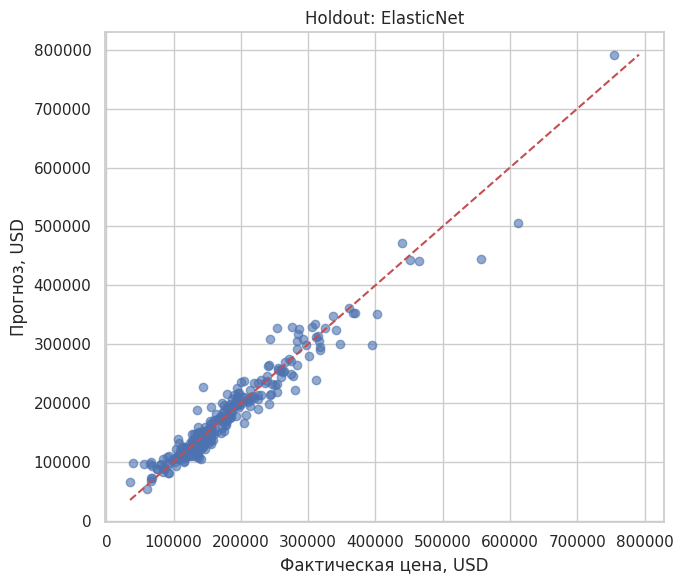

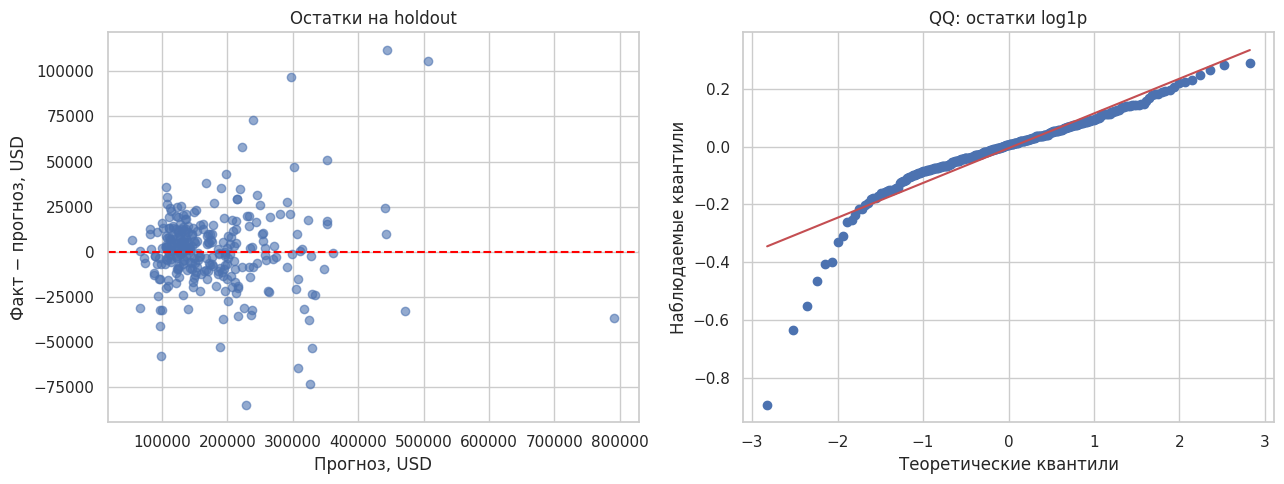

,Id,actual,prediction,residual,abs_error
1046,1047,556581.0,444693.279300,111887.720700,111887.720700
898,899,611657.0,506045.244884,105611.755116,105611.755116
774,775,395000.0,297813.015936,97186.984064,97186.984064
588,589,143000.0,227935.511741,-84935.511741,84935.511741
581,582,253293.0,326741.783081,-73448.783081,73448.783081


Среднее остатка USD: 877.8971748926375 Std USD: 21649.768543170565


По CV выбрана **ElasticNet**. На holdout RMSE(log) = **0.1292**, R²(log) = **0.9106**, R²(USD) = **0.9390**.

In [5]:
# Вычисляем метрики в двух шкалах, сохраняя предсказания каждой модели.
rows, predictions = [], {}
actual = np.expm1(y_valid)
for name, model in models.items():
    z = model.predict(X_valid)
    prices = np.expm1(z)
    predictions[name] = prices
    rows.append({'model':name, 'rmse_log':np.sqrt(mean_squared_error(y_valid,z)),
                 'mae_log':mean_absolute_error(y_valid,z), 'r2_log':r2_score(y_valid,z),
                 'rmse_usd':np.sqrt(mean_squared_error(actual,prices)),
                 'mae_usd':mean_absolute_error(actual,prices), 'r2_usd':r2_score(actual,prices)})
metrics = pd.DataFrame(rows).set_index('model')
display(metrics)
pred = predictions[best_name]
residuals = actual - pred
fig, ax = plt.subplots(figsize=(7,6))
ax.scatter(actual, pred, alpha=.6)
lims = [min(actual.min(),pred.min()),max(actual.max(),pred.max())]
ax.plot(lims,lims,'r--')
ax.set(xlabel='Фактическая цена, USD', ylabel='Прогноз, USD', title=f'Holdout: {best_name}')
fig.tight_layout()
fig.savefig('examples/predictions_scatter.png', dpi=140)
plt.show()
# Диагностика остатков: доллары и QQ-график логарифмических ошибок.
fig, axes = plt.subplots(1,2,figsize=(13,5))
axes[0].scatter(pred,residuals,alpha=.6)
axes[0].axhline(0,color='red',linestyle='--')
axes[0].set(xlabel='Прогноз, USD',ylabel='Факт − прогноз, USD',title='Остатки на holdout')
stats.probplot(y_valid-best_model.predict(X_valid), dist='norm', plot=axes[1])
axes[1].set(title='QQ: остатки log1p',xlabel='Теоретические квантили',ylabel='Наблюдаемые квантили')
fig.tight_layout()
fig.savefig('examples/residuals.png',dpi=140)
plt.show()
worst = pd.DataFrame({'Id':train_df.loc[X_valid.index,'Id'], 'actual':actual,
                     'prediction':pred, 'residual':residuals})
display(worst.assign(abs_error=abs(residuals)).nlargest(5,'abs_error'))
print('Среднее остатка USD:',residuals.mean(), 'Std USD:',residuals.std())
display(Markdown(f'По CV выбрана **{best_name}**. На holdout RMSE(log) = **{metrics.loc[best_name,"rmse_log"]:.4f}**, '
                 f'R²(log) = **{metrics.loc[best_name,"r2_log"]:.4f}**, R²(USD) = **{metrics.loc[best_name,"r2_usd"]:.4f}**.'))

Точки дальше от диагонали — дома с большей ошибкой. Крупные долларовые остатки
у дорогих домов могут сохраняться даже после обучения на логарифмах.
QQ-график помогает увидеть отклонения хвостов от нормального распределения;
не считаем нормальность или гомоскедастичность доказанными.
Таблица самых больших ошибок показывает случаи, где линейной модели недостаёт информации:
особые условия продажи, редкий район и необычные сочетания качества и площади.
Отдельная ошибка не доказывает ошибку данных. Holdout не удаляем и параметры по нему не подбираем.

## 8. Интерпретация
Числовые коэффициенты относятся к изменению на одно стандартное отклонение признака.
Категориальные коэффициенты сравниваются с пропущенной базовой категорией (drop=first).
Величина $100(\exp(w)-1)$ — изменение прогнозируемой цены в процентах при таком
изменении одного столбца. При связанных признаках и взаимодействиях это не эффект
физического изменения одного параметра дома и не причинный вывод.

,Положительные коэффициенты
Neighborhood_Crawfor,0.077426
GrLivArea,0.074411
SaleCondition_Partial,0.072608
Exterior1st_BrkFace,0.069840
OverallQual,0.067552


,Отрицательные коэффициенты
MSSubClass_160,-0.075562
MSZoning_RM,-0.048638
HouseAge,-0.048122
MSSubClass_30,-0.035611
RemodAge,-0.016631


Lasso обнулил: 155 из 261


,|Lasso coefficient|
Neighborhood_Crawfor,0.089038
MSSubClass_160,0.086902
SaleCondition_Partial,0.086274
Neighborhood_StoneBr,0.079620
GrLivArea,0.075336
Exterior1st_BrkFace,0.075044
TotalSF,0.065098
Functional_Typ,0.064525
OverallQual,0.063266
HouseAge,0.051822


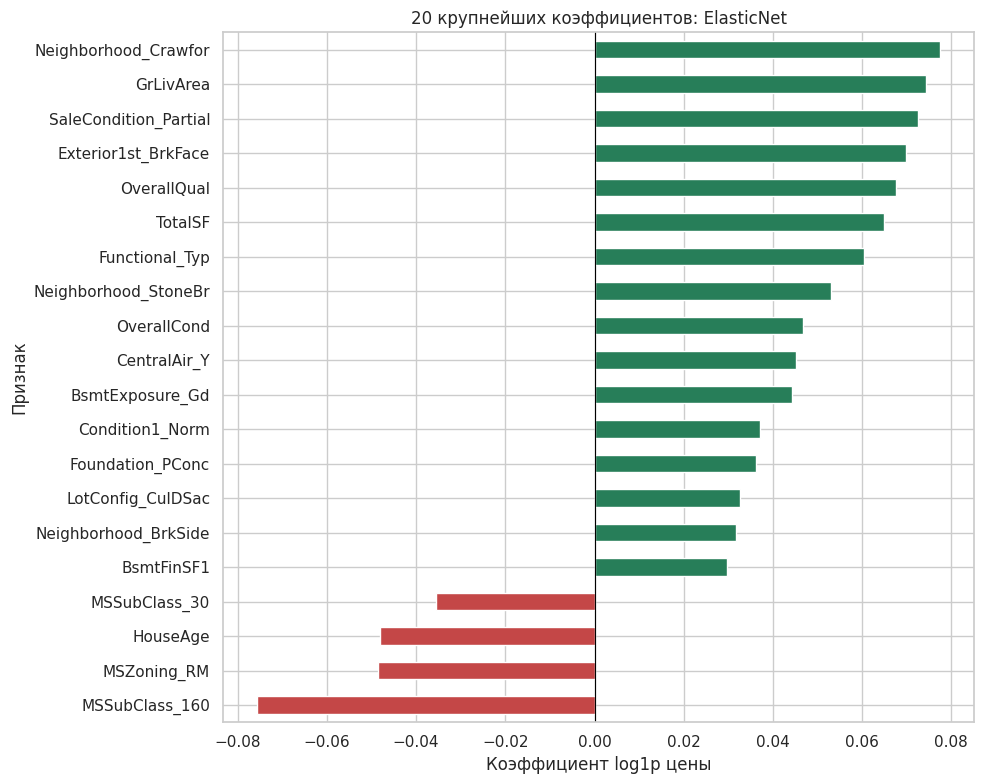

In [6]:
# Имена кодированных признаков получаем из fitted ColumnTransformer.
coef_tables = {}
for name, model in models.items():
    names = model.named_steps['preprocess'].get_feature_names_out()
    coef_tables[name] = pd.Series(model.named_steps['model'].coef_,index=names,name=name)
coefs = coef_tables[best_name]
display(coefs.nlargest(5).to_frame('Положительные коэффициенты'))
display(coefs.nsmallest(5).to_frame('Отрицательные коэффициенты'))
lasso_coef = coef_tables['Lasso']
print('Lasso обнулил:', int((lasso_coef == 0).sum()), 'из', len(lasso_coef))
display(lasso_coef[lasso_coef != 0].abs().nlargest(15).to_frame('|Lasso coefficient|'))
top_coef = coefs.loc[coefs.abs().nlargest(20).index].sort_values()
fig, ax = plt.subplots(figsize=(10,8))
top_coef.plot.barh(ax=ax,color=['#c44747' if v<0 else '#277e59' for v in top_coef])
ax.axvline(0,color='black',linewidth=.8)
ax.set(title=f'20 крупнейших коэффициентов: {best_name}',xlabel='Коэффициент log1p цены',ylabel='Признак')
fig.tight_layout()
fig.savefig('examples/coefficients.png',dpi=140)
plt.show()

Практические выводы: оценивать площадь стоит вместе с качеством отделки;
район и условия продажи нужны даже при одинаковом размере дома;
площадь и вместимость гаража частично дублируют информацию.
Регуляризация уменьшает нестабильность связанных коэффициентов, а Lasso дополнительно
упрощает набор активных признаков. Коэффициент бассейна по нескольким редким примерам
не даёт надёжной оценки окупаемости строительства бассейна.
Для оценки стоимости ремонта нужен отдельный причинный анализ.

## 9. Функция предсказания
`predict_price(house_data, model)` принимает исходные поля CSV и возвращает доллары.
Весь обученный путь преобразований находится в model: ручное кодирование и повторный
fit при предсказании не нужны. Пропущенные необязательные поля импутируются по обучению.
Для осмысленного запроса обязательны OverallQual, GrLivArea, YearBuilt и Neighborhood.
Покажем пять реальных домов разных ценовых уровней и один неполный запрос.

In [7]:
# Пять объектов holdout по квантилям фактической цены, без повторного обучения.
ordered = y_valid.sort_values().index
demo_idx = ordered[np.linspace(0,len(ordered)-1,5,dtype=int)]
demo = X_valid.loc[demo_idx]
demo_table = demo[['OverallQual','GrLivArea','YearBuilt','GarageCars']].copy()
demo_table['Факт USD'] = np.expm1(y_valid.loc[demo_idx])
demo_table['Прогноз USD'] = predict_price(demo,best_model)
demo_table['Ошибка USD'] = demo_table['Прогноз USD'] - demo_table['Факт USD']
display(demo_table)
# Словарь одного дома возвращает float; неизвестная категория не ломает схему.
partial = {'OverallQual':6,'GrLivArea':1500,'YearBuilt':2000,'Neighborhood':'CollgCr'}
print('Неполный запрос USD:',predict_price(partial,best_model))
new_area = dict(partial, Neighborhood='NewNeighborhood')
print('Новый район USD:',predict_price(new_area,best_model))

,OverallQual,GrLivArea,YearBuilt,GarageCars,Факт USD,Прогноз USD,Ошибка USD
916,2,480,1949,1,35311.0,66645.392755,31334.392755
49,5,955,1966,1,127000.0,132210.957800,5210.957800
1299,5,1246,1959,1,154000.0,164783.686250,10783.686250
1317,7,1352,2006,2,208900.0,204504.014844,-4395.985156
691,10,4316,1994,3,755000.0,791861.135850,36861.135850


Неполный запрос USD: 136406.4821648589
Новый район USD: 136406.4821648589


Демонстрация использует дома от дешёвого до дорогого и показывает ошибки каждого.
Цена неполного запроса условна: неизвестные характеристики заменяются типичными
обучающими значениями. Применимость ограничена Эймсом и периодом 2006–2010;
для современных домов в другом городе модель нужно обучать на соответствующих продажах.

## 10. Сохранение модели
Сохраняем четыре **полных пайплайна**, выбранную модель, scaler и порядок преобразованных
признаков. Отдельный scaler нужен для структуры задания; при инференсе используем
полный pipeline, чтобы не масштабировать данные дважды. Сохранённые модели обучены
на той же обучающей части, для которой получены holdout-метрики; скрытого refit на holdout нет.

In [8]:
# Имена артефактов соответствуют методичке; файл best_model — полный pipeline.
filenames = {'Linear Regression':'lr_model.pkl','Ridge':'ridge_model.pkl',
             'Lasso':'lasso_model.pkl','ElasticNet':'enet_model.pkl'}
for name, model in models.items():
    joblib.dump(model,Path('models')/filenames[name],compress=3)
joblib.dump(best_model,'models/best_model.pkl',compress=3)
prep = best_model.named_steps['preprocess']
joblib.dump(prep.named_transformers_['num'].named_steps['scale'],'models/scaler.pkl')
names = prep.get_feature_names_out().tolist()
Path('models/feature_cols.json').write_text(json.dumps(names,ensure_ascii=False,indent=2),encoding='utf-8')
Path('models/metrics.json').write_text(metrics.to_json(orient='index',indent=2),encoding='utf-8')
Path('models/training.json').write_text(training.to_json(orient='index',indent=2),encoding='utf-8')
# Сохраняем разделение, версии и контрольные суммы для повторения эксперимента.
metadata = {'author':'Федорушкин Станислав','group':'ПКТб-23-1','date':'2026-10-27',
            'best_model':best_name,'selection_metric':'5-fold CV RMSE(log1p)',
            'random_state':42,'n_train':len(X_train),'n_holdout':len(X_valid),
            'train_ids':train_df.loc[X_train.index,'Id'].tolist(),
            'holdout_ids':train_df.loc[X_valid.index,'Id'].tolist(),
            'removed_ids':eda.loc[outlier_mask,'Id'].tolist(),
            'python':platform.python_version(),
            'versions':{p:md.version(p) for p in ['numpy','pandas','scikit-learn','scipy','joblib']},
            'sha256':{p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in Path('data').glob('*.csv')},
            'refit_on_holdout':False}
Path('models/metadata.json').write_text(json.dumps(metadata,ensure_ascii=False,indent=2),encoding='utf-8')
metrics.to_csv('examples/metrics.csv')
submission = pd.DataFrame({'Id':test_df.Id,'SalePrice':predict_price(test_df,best_model)})
assert len(submission)==1459 and submission.SalePrice.gt(0).all()
submission.to_csv('submission.csv',index=False)
print('Артефакты сохранены; submission:',submission.shape)

Артефакты сохранены; submission: (1459, 2)


`best_model.pkl` включает импутацию, feature engineering, кодирование и модель.
Для загрузки доступен импортируемый `housing_pipeline.py`. Сохранены также все ID разбиения
и версии библиотек. `submission.csv` содержит все 1459 прогнозов; отправка на Kaggle не выполнялась.

## 11. Загрузка модели из репозитория
Raw-адрес подготовлен для собственного репозитория. Пока файлы не опубликованы,
выполняем проверку локальной загрузки; это явно не считается проверкой GitHub.
После push установите `HOUSE_PRICES_VERIFY_REMOTE=1` и выполните ячейку снова:
HTTP-ошибки будут видимы, а прогнозы трёх домов должны совпасть.
Для использования нужен `housing_pipeline.py` из того же модуля и те же версии зависимостей.

In [9]:
# Проверяем joblib round-trip на трёх исходных домах без переобучения.
BASE_URL = 'https://raw.githubusercontent.com/Ogn1k/ml-course-fedorushkin/main/module-2-house-prices'
loaded = joblib.load('models/best_model.pkl')
reference = predict_price(demo.iloc[:3],best_model)
np.testing.assert_allclose(predict_price(demo.iloc[:3],loaded),reference,rtol=1e-12)
print('Локальная загрузка: три прогноза совпали')
# Включается только для реальной проверки уже опубликованного файла.
if os.environ.get('HOUSE_PRICES_VERIFY_REMOTE') == '1':
    remote = load_remote_model(BASE_URL)
    np.testing.assert_allclose(predict_price(demo.iloc[:3],remote),reference,rtol=1e-12)
    print('GitHub raw: загрузка выполнена, три прогноза совпали')
else:
    print('GitHub raw не проверен: требуется публикация файлов и HOUSE_PRICES_VERIFY_REMOTE=1')

Локальная загрузка: три прогноза совпали
GitHub raw не проверен: требуется публикация файлов и HOUSE_PRICES_VERIFY_REMOTE=1


Локальное восстановление проверено численно. Удалённая проверка остаётся шагом
после публикации; код не подменяет сетевую загрузку локальной в случае HTTP-ошибки.

## 12. Выводы
Обучены четыре линейные модели с одинаковым разделением и предобработкой внутри CV.
Следующая ячейка формирует итог из фактических результатов, включая время и достижение ориентира R².

In [10]:
# Подставляем измеренные результаты, не используя примерные цифры методички.
m = metrics.loc[best_name]
display(Markdown(f"Лучшая модель по CV: **{best_name}**. "
                 f"Holdout: RMSE(log) **{m.rmse_log:.4f}**, MAE **${m.mae_usd:,.0f}**, "
                 f"RMSE **${m.rmse_usd:,.0f}**, R²(USD) **{m.r2_usd:.4f}**, R²(log) **{m.r2_log:.4f}**. "
                 f"Финальное обучение: **{training.loc[best_name,'fit_seconds']:.3f} с**, "
                 f"поиск: **{training.loc[best_name,'search_seconds']:.2f} с**. "
                 f"Ориентир R²(USD) ≥ 0.90: **{'достигнут' if m.r2_usd >= .90 else 'не достигнут'}**."))

Лучшая модель по CV: **ElasticNet**. Holdout: RMSE(log) **0.1292**, MAE **$14,426**, RMSE **$21,630**, R²(USD) **0.9390**, R²(log) **0.9106**. Финальное обучение: **0.249 с**, поиск: **17.35 с**. Ориентир R²(USD) ≥ 0.90: **достигнут**.

Ключевые наблюдения: качество и площади связаны с ценой, целевая имеет правый хвост,
гаражные признаки коррелируют. Смысловые и неизвестные пропуски пришлось обрабатывать
по-разному. Дополнительная трудность — сохранение одинакового порядка категорий при инференсе;
это решено сохранением целого Pipeline. Полного устранения крупных ошибок и хвостов
остатков линейными моделями ожидать нельзя. Онлайн-загрузка из GitHub требует публикации.

Возможные улучшения:
1. Проверить Gradient Boosting / XGBoost с отдельным бюджетом настройки.
2. Добавить Target Encoding района строго с cross-fitting внутри CV.
3. Проверить отбор признаков RFE на обучающих фолдах.
4. Использовать Optuna с вложенной CV для менее смещённого сравнения.
5. Сравнить stacking с out-of-fold предсказаниями базовых моделей.
6. Оценить интервалы неопределённости и устойчивость по годам продажи.

Случайный holdout оценивает похожие продажи того же периода; перенос на другой город
или год требует отдельной проверки. `expm1` лог-прогноза не гарантирует несмещённое
условное среднее цены; коррекцию обратного преобразования можно исследовать на CV.

## 13. Список источников
1. Учебные материалы из каталогов «Теория» и «Практика»: полная теория, слайды,
   описание House Prices и практическое задание модуля 2 (локальные материалы курса).
2. [Kaggle: House Prices — Advanced Regression Techniques](https://www.kaggle.com/c/house-prices-advanced-regression-techniques/data).
3. De Cock, D. (2011). [Ames, Iowa: Alternative to the Boston Housing Data as an End of Semester Regression Project](https://jse.amstat.org/v19n3/decock.pdf). Journal of Statistics Education, 19(3).
4. [Scikit-learn: Pipelines and composite estimators](https://scikit-learn.org/stable/modules/compose.html).
5. [Scikit-learn: Linear Models](https://scikit-learn.org/stable/modules/linear_model.html).
6. [Pandas: Working with missing data](https://pandas.pydata.org/docs/user_guide/missing_data.html).
7. [Зеркало исходных CSV Rswcf/houseprices_kaggle](https://github.com/Rswcf/houseprices_kaggle).
   Использованы только CSV и словарь, не готовое решение.
8. McKinney, W. (2022). *Python for Data Analysis*, 3rd ed. O’Reilly.
9. James, G., Witten, D., Hastie, T., Tibshirani, R. (2021). *An Introduction to Statistical Learning*, 2nd ed. Springer.

Код и текст подготовлены с помощью OpenAI Codex; фактические выводы доступны в выполненных ячейках.

## 14. Приложение
Полный код всех вычислительных ячеек с разделителями `# %%` находится в
`appendix_full_code.py`; код преобразований и инференса — в `housing_pipeline.py`.
Точные версии среды записаны в `requirements.txt` и метаданных. Ниже полный исходный
код приложения; для обычного запуска достаточно последовательно выполнить предыдущие разделы.

```python
# Зависимости: requirements.txt
# %%
# Импортируем библиотеки и ограничиваем BLAS для воспроизводимого времени.
import os
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['OPENBLAS_NUM_THREADS'] = '1'
from pathlib import Path
import json
import time
import platform
import warnings
import hashlib
import importlib.metadata as md
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display, Markdown
from scipy import stats
from threadpoolctl import threadpool_limits
from sklearn.base import clone
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from housing_pipeline import make_pipeline, predict_price, load_remote_model

# Новые категории ожидаемы внутри CV: ignore кодирует их нулями.
# Скрываем только повторяющееся уведомление энкодера, остальные предупреждения видны.
warnings.filterwarnings('ignore', message='Found unknown categories in columns.*',
                        category=UserWarning, module=r'sklearn\.preprocessing\._encoders')
# Запускаем notebook из каталога модуля; все файлы имеют относительные пути.
assert Path('housing_pipeline.py').exists(), 'Запускайте из module-2-house-prices'
for folder in ['models', 'examples']:
    Path(folder).mkdir(exist_ok=True)
sns.set_theme(style='whitegrid', font='DejaVu Sans')
train_df = pd.read_csv('data/train.csv', keep_default_na=False, na_values=['NA', ''])
test_df = pd.read_csv('data/test.csv', keep_default_na=False, na_values=['NA', ''])
print(train_df.shape, test_df.shape)
assert train_df.shape == (1460, 81) and test_df.shape == (1459, 80)
assert train_df.Id.is_unique and test_df.Id.is_unique
assert set(train_df.Id).isdisjoint(test_df.Id)
display(train_df.head())
train_df.info()
display(train_df.describe())
# Статистики считаются по данным: текстовые категории None не теряются при чтении.
display(train_df.SalePrice.describe().to_frame())
print('skew:', train_df.SalePrice.skew(), 'kurtosis:', train_df.SalePrice.kurtosis())
print('Числовых признаков:', train_df.drop(columns=['Id','SalePrice']).select_dtypes('number').shape[1])

# %%
# Отделяем Id и цель; SalePrice_log никогда не входит в признаки.
X = train_df.drop(columns=['Id', 'SalePrice'])
y = np.log1p(train_df.SalePrice)
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=.2, random_state=42)
eda = train_df.loc[X_train.index].copy()
missing = eda.isna().sum().sort_values(ascending=False)
display(missing[missing > 0].to_frame('Пропусков'))
q1, q3 = eda.GrLivArea.quantile([.25, .75])
iqr_mask = (eda.GrLivArea < q1-1.5*(q3-q1)) | (eda.GrLivArea > q3+1.5*(q3-q1))
outlier_mask = (X_train.GrLivArea > 4000) & (np.expm1(y_train) < 300000)
print('IQR кандидатов:', iqr_mask.sum(), 'Удаляем по доменному правилу:', outlier_mask.sum())
display(eda.loc[outlier_mask, ['Id', 'GrLivArea', 'SalePrice']])

# Шесть графиков с отдельными заголовками и подписями осей.
fig, axes = plt.subplots(2, 3, figsize=(19, 11))
sns.histplot(eda.SalePrice, kde=True, ax=axes[0,0])
axes[0,0].set(title='Цена продажи', xlabel='SalePrice, USD', ylabel='Число домов')
sns.histplot(np.log1p(eda.SalePrice), kde=True, ax=axes[0,1])
axes[0,1].set(title='Логарифм цены', xlabel='log1p(SalePrice)', ylabel='Число домов')
top = eda.select_dtypes('number').corr().SalePrice.abs().nlargest(11).index
sns.heatmap(eda[top].corr(), cmap='coolwarm', center=0, ax=axes[0,2])
axes[0,2].set(title='Корреляции 10 признаков и цели', xlabel='Признак', ylabel='Признак')
sns.boxplot(data=eda, x='OverallQual', y='GrLivArea', ax=axes[1,0])
axes[1,0].set(title='Площадь и качество', xlabel='OverallQual, баллы', ylabel='GrLivArea, кв. футы')
sns.scatterplot(data=eda, x='GrLivArea', y='SalePrice', hue=outlier_mask.map({True:'Удаляем',False:'Оставляем'}), ax=axes[1,1])
axes[1,1].set(title='Выбросы площади и цены', xlabel='GrLivArea, кв. футы', ylabel='Цена, USD')
(missing[missing > 0] / len(eda) * 100).sort_values().plot.barh(ax=axes[1,2])
axes[1,2].set(title='Пропуски', xlabel='Доля, %', ylabel='Признак')
fig.tight_layout()
fig.savefig('examples/eda_plots.png', dpi=140)
plt.show()
print('Асимметрия до/после log1p:', eda.SalePrice.skew(), np.log1p(eda.SalePrice).skew())
print('Корреляция GarageCars/GarageArea:', eda.GarageCars.corr(eda.GarageArea))
# Убираем аномалии только из обучения; все 292 holdout-дома сохраняются.
X_train, y_train = X_train.loc[~outlier_mask], y_train.loc[~outlier_mask]
print('Размер обучения и holdout:', len(X_train), len(X_valid))

# %%
# Показываем, что признаки создаются без изучения holdout и без целевой переменной.
preview_pipeline = make_pipeline(Ridge())
prepared = preview_pipeline[:-1].fit_transform(X_train, y_train)
feature_names = preview_pipeline.named_steps['preprocess'].get_feature_names_out().tolist()
assert np.isfinite(prepared).all()
assert 'SalePrice' not in feature_names and 'Id' not in feature_names
print('После преобразований:', prepared.shape, 'NaN:', np.isnan(prepared).sum())
display(preview_pipeline.named_steps['features'].transform(X_train).head())

# %%
# Сетки заданы до просмотра результатов holdout.
cv = KFold(n_splits=5, shuffle=True, random_state=42)
specs = {
    'Linear Regression': (LinearRegression(), {}),
    'Ridge': (Ridge(), {'model__alpha': [.1, 1, 10, 30, 100]}),
    'Lasso': (Lasso(max_iter=30000, tol=1e-5), {'model__alpha': [.0001, .0003, .0005, .001, .003]}),
    'ElasticNet': (ElasticNet(max_iter=30000, tol=1e-5),
                   {'model__alpha': [.0003, .001, .003], 'model__l1_ratio': [.2, .5, .8]})
}
models, training_rows, searches = {}, [], {}
with threadpool_limits(limits=1):
    for name, (regressor, grid) in specs.items():
        # GridSearch обучает весь pipeline внутри каждого CV-разбиения.
        start = time.perf_counter()
        search = GridSearchCV(make_pipeline(regressor), grid, cv=cv,
                              scoring='neg_root_mean_squared_error', n_jobs=1, error_score='raise')
        search.fit(X_train, y_train)
        elapsed = time.perf_counter() - start
        models[name], searches[name] = search.best_estimator_, search
        idx = search.best_index_
        training_rows.append({'model': name, 'cv_rmse_log': -search.best_score_,
                              'cv_std': search.cv_results_['std_test_score'][idx],
                              'search_seconds': elapsed, 'fit_seconds': search.refit_time_,
                              'parameters': search.best_params_})
training = pd.DataFrame(training_rows).set_index('model')
best_name = training.cv_rmse_log.idxmin()
best_model = models[best_name]
display(training)
print('Выбрана до проверки holdout:', best_name)

# %%
# Вычисляем метрики в двух шкалах, сохраняя предсказания каждой модели.
rows, predictions = [], {}
actual = np.expm1(y_valid)
for name, model in models.items():
    z = model.predict(X_valid)
    prices = np.expm1(z)
    predictions[name] = prices
    rows.append({'model':name, 'rmse_log':np.sqrt(mean_squared_error(y_valid,z)),
                 'mae_log':mean_absolute_error(y_valid,z), 'r2_log':r2_score(y_valid,z),
                 'rmse_usd':np.sqrt(mean_squared_error(actual,prices)),
                 'mae_usd':mean_absolute_error(actual,prices), 'r2_usd':r2_score(actual,prices)})
metrics = pd.DataFrame(rows).set_index('model')
display(metrics)
pred = predictions[best_name]
residuals = actual - pred
fig, ax = plt.subplots(figsize=(7,6))
ax.scatter(actual, pred, alpha=.6)
lims = [min(actual.min(),pred.min()),max(actual.max(),pred.max())]
ax.plot(lims,lims,'r--')
ax.set(xlabel='Фактическая цена, USD', ylabel='Прогноз, USD', title=f'Holdout: {best_name}')
fig.tight_layout()
fig.savefig('examples/predictions_scatter.png', dpi=140)
plt.show()
# Диагностика остатков: доллары и QQ-график логарифмических ошибок.
fig, axes = plt.subplots(1,2,figsize=(13,5))
axes[0].scatter(pred,residuals,alpha=.6)
axes[0].axhline(0,color='red',linestyle='--')
axes[0].set(xlabel='Прогноз, USD',ylabel='Факт − прогноз, USD',title='Остатки на holdout')
stats.probplot(y_valid-best_model.predict(X_valid), dist='norm', plot=axes[1])
axes[1].set(title='QQ: остатки log1p',xlabel='Теоретические квантили',ylabel='Наблюдаемые квантили')
fig.tight_layout()
fig.savefig('examples/residuals.png',dpi=140)
plt.show()
worst = pd.DataFrame({'Id':train_df.loc[X_valid.index,'Id'], 'actual':actual,
                     'prediction':pred, 'residual':residuals})
display(worst.assign(abs_error=abs(residuals)).nlargest(5,'abs_error'))
print('Среднее остатка USD:',residuals.mean(), 'Std USD:',residuals.std())
display(Markdown(f'По CV выбрана **{best_name}**. На holdout RMSE(log) = **{metrics.loc[best_name,"rmse_log"]:.4f}**, '
                 f'R²(log) = **{metrics.loc[best_name,"r2_log"]:.4f}**, R²(USD) = **{metrics.loc[best_name,"r2_usd"]:.4f}**.'))

# %%
# Имена кодированных признаков получаем из fitted ColumnTransformer.
coef_tables = {}
for name, model in models.items():
    names = model.named_steps['preprocess'].get_feature_names_out()
    coef_tables[name] = pd.Series(model.named_steps['model'].coef_,index=names,name=name)
coefs = coef_tables[best_name]
display(coefs.nlargest(5).to_frame('Положительные коэффициенты'))
display(coefs.nsmallest(5).to_frame('Отрицательные коэффициенты'))
lasso_coef = coef_tables['Lasso']
print('Lasso обнулил:', int((lasso_coef == 0).sum()), 'из', len(lasso_coef))
display(lasso_coef[lasso_coef != 0].abs().nlargest(15).to_frame('|Lasso coefficient|'))
top_coef = coefs.loc[coefs.abs().nlargest(20).index].sort_values()
fig, ax = plt.subplots(figsize=(10,8))
top_coef.plot.barh(ax=ax,color=['#c44747' if v<0 else '#277e59' for v in top_coef])
ax.axvline(0,color='black',linewidth=.8)
ax.set(title=f'20 крупнейших коэффициентов: {best_name}',xlabel='Коэффициент log1p цены',ylabel='Признак')
fig.tight_layout()
fig.savefig('examples/coefficients.png',dpi=140)
plt.show()

# %%
# Пять объектов holdout по квантилям фактической цены, без повторного обучения.
ordered = y_valid.sort_values().index
demo_idx = ordered[np.linspace(0,len(ordered)-1,5,dtype=int)]
demo = X_valid.loc[demo_idx]
demo_table = demo[['OverallQual','GrLivArea','YearBuilt','GarageCars']].copy()
demo_table['Факт USD'] = np.expm1(y_valid.loc[demo_idx])
demo_table['Прогноз USD'] = predict_price(demo,best_model)
demo_table['Ошибка USD'] = demo_table['Прогноз USD'] - demo_table['Факт USD']
display(demo_table)
# Словарь одного дома возвращает float; неизвестная категория не ломает схему.
partial = {'OverallQual':6,'GrLivArea':1500,'YearBuilt':2000,'Neighborhood':'CollgCr'}
print('Неполный запрос USD:',predict_price(partial,best_model))
new_area = dict(partial, Neighborhood='NewNeighborhood')
print('Новый район USD:',predict_price(new_area,best_model))

# %%
# Имена артефактов соответствуют методичке; файл best_model — полный pipeline.
filenames = {'Linear Regression':'lr_model.pkl','Ridge':'ridge_model.pkl',
             'Lasso':'lasso_model.pkl','ElasticNet':'enet_model.pkl'}
for name, model in models.items():
    joblib.dump(model,Path('models')/filenames[name],compress=3)
joblib.dump(best_model,'models/best_model.pkl',compress=3)
prep = best_model.named_steps['preprocess']
joblib.dump(prep.named_transformers_['num'].named_steps['scale'],'models/scaler.pkl')
names = prep.get_feature_names_out().tolist()
Path('models/feature_cols.json').write_text(json.dumps(names,ensure_ascii=False,indent=2),encoding='utf-8')
Path('models/metrics.json').write_text(metrics.to_json(orient='index',indent=2),encoding='utf-8')
Path('models/training.json').write_text(training.to_json(orient='index',indent=2),encoding='utf-8')
# Сохраняем разделение, версии и контрольные суммы для повторения эксперимента.
metadata = {'author':'Федорушкин Станислав','group':'ПКТб-23-1','date':'2026-10-27',
            'best_model':best_name,'selection_metric':'5-fold CV RMSE(log1p)',
            'random_state':42,'n_train':len(X_train),'n_holdout':len(X_valid),
            'train_ids':train_df.loc[X_train.index,'Id'].tolist(),
            'holdout_ids':train_df.loc[X_valid.index,'Id'].tolist(),
            'removed_ids':eda.loc[outlier_mask,'Id'].tolist(),
            'python':platform.python_version(),
            'versions':{p:md.version(p) for p in ['numpy','pandas','scikit-learn','scipy','joblib']},
            'sha256':{p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in Path('data').glob('*.csv')},
            'refit_on_holdout':False}
Path('models/metadata.json').write_text(json.dumps(metadata,ensure_ascii=False,indent=2),encoding='utf-8')
metrics.to_csv('examples/metrics.csv')
submission = pd.DataFrame({'Id':test_df.Id,'SalePrice':predict_price(test_df,best_model)})
assert len(submission)==1459 and submission.SalePrice.gt(0).all()
submission.to_csv('submission.csv',index=False)
print('Артефакты сохранены; submission:',submission.shape)

# %%
# Проверяем joblib round-trip на трёх исходных домах без переобучения.
BASE_URL = 'https://raw.githubusercontent.com/Ogn1k/ml-course-fedorushkin/main/module-2-house-prices'
loaded = joblib.load('models/best_model.pkl')
reference = predict_price(demo.iloc[:3],best_model)
np.testing.assert_allclose(predict_price(demo.iloc[:3],loaded),reference,rtol=1e-12)
print('Локальная загрузка: три прогноза совпали')
# Включается только для реальной проверки уже опубликованного файла.
if os.environ.get('HOUSE_PRICES_VERIFY_REMOTE') == '1':
    remote = load_remote_model(BASE_URL)
    np.testing.assert_allclose(predict_price(demo.iloc[:3],remote),reference,rtol=1e-12)
    print('GitHub raw: загрузка выполнена, три прогноза совпали')
else:
    print('GitHub raw не проверен: требуется публикация файлов и HOUSE_PRICES_VERIFY_REMOTE=1')

# %%
# Подставляем измеренные результаты, не используя примерные цифры методички.
m = metrics.loc[best_name]
display(Markdown(f"Лучшая модель по CV: **{best_name}**. "
                 f"Holdout: RMSE(log) **{m.rmse_log:.4f}**, MAE **${m.mae_usd:,.0f}**, "
                 f"RMSE **${m.rmse_usd:,.0f}**, R²(USD) **{m.r2_usd:.4f}**, R²(log) **{m.r2_log:.4f}**. "
                 f"Финальное обучение: **{training.loc[best_name,'fit_seconds']:.3f} с**, "
                 f"поиск: **{training.loc[best_name,'search_seconds']:.2f} с**. "
                 f"Ориентир R²(USD) ≥ 0.90: **{'достигнут' if m.r2_usd >= .90 else 'не достигнут'}**."))
```

```python
"""Предобработка House Prices и инференс; классы доступны при joblib.load."""
from io import BytesIO

import numpy as np
import pandas as pd
import requests
import joblib
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


class HouseFeatures(TransformerMixin, BaseEstimator):
    """Изучает импутацию только на fit; transform не использует SalePrice."""

    def fit(self, X, y=None):
        # Запоминаем исходную схему и медианы районов только обучающей части.
        self.feature_names_in_ = np.array(X.columns, dtype=object)
        self.frontage_ = X.groupby('Neighborhood')['LotFrontage'].median()
        self.frontage_default_ = X['LotFrontage'].median()
        return self

    def transform(self, X):
        # Пропущенные входные поля восстанавливаем как NaN, а не как ложные нули.
        d = X.reindex(columns=self.feature_names_in_).copy()
        d['LotFrontage'] = d['LotFrontage'].fillna(
            d['Neighborhood'].map(self.frontage_)).fillna(self.frontage_default_)
        # Указанные NA в описании означают отсутствие сооружения/элемента.
        absent = ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu',
                  'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
                  'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2']
        for col in absent:
            d[col] = d[col].fillna('None')
        # Числовые пропуски обнуляем только при подтверждённом отсутствии объекта.
        groups = {'GarageType': ['GarageArea', 'GarageCars'],
                  'BsmtQual': ['BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF',
                               'TotalBsmtSF', 'BsmtFullBath', 'BsmtHalfBath']}
        for indicator, cols in groups.items():
            for col in cols:
                d.loc[d[indicator].eq('None'), col] = d.loc[d[indicator].eq('None'), col].fillna(0)
        # None в MasVnrType является категорией в CSV; потерянные значения — Unknown.
        d['MasVnrType'] = d['MasVnrType'].fillna('Unknown')
        d.loc[d['MasVnrType'].eq('None'), 'MasVnrArea'] = 0
        # Качество кодируем в известном порядке; неизвестные значения оставляем импутеру.
        quality = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
        for col in ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC',
                    'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC']:
            d[col] = d[col].map(quality)
        # Номинальные числовые коды не задают линейного порядка классов.
        for col in ['MSSubClass', 'MoSold']:
            d[col] = d[col].map(lambda v: str(int(v)) if pd.notna(v) else np.nan)
        # Агрегации сохраняют NaN, если часть неизвестна: импутация будет внутри CV.
        d['TotalSF'] = d[['TotalBsmtSF', '1stFlrSF', '2ndFlrSF']].sum(axis=1, min_count=3)
        d['TotalBath'] = d['FullBath'] + .5*d['HalfBath'] + d['BsmtFullBath'] + .5*d['BsmtHalfBath']
        porches = ['OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'WoodDeckSF']
        d['TotalPorch'] = d[porches].sum(axis=1, min_count=len(porches))
        d['HouseAge'] = (d['YrSold'] - d['YearBuilt']).clip(lower=0)
        d['RemodAge'] = (d['YrSold'] - d['YearRemodAdd']).clip(lower=0)
        # Год гаража не превращаем в фиктивный древний год при отсутствии гаража.
        d['GarageAge'] = (d['YrSold'] - d['GarageYrBlt']).clip(lower=0)
        d.loc[d['GarageType'].eq('None'), 'GarageAge'] = 0
        d = d.drop(columns='GarageYrBlt')
        for name, col in {'HasPool':'PoolArea', 'HasGarage':'GarageArea',
                          'Has2ndFloor':'2ndFlrSF', 'HasFireplace':'Fireplaces',
                          'HasBsmt':'TotalBsmtSF'}.items():
            d[name] = np.where(d[col].isna(), np.nan, (d[col] > 0).astype(float))
        d['OverallQual_TotalSF'] = d['OverallQual'] * d['TotalSF']
        return d


def make_pipeline(model):
    # Каждый fit в CV заново обучает импутацию, категории и масштабирование.
    num = Pipeline([('impute', SimpleImputer(strategy='median', keep_empty_features=True)),
                    ('scale', StandardScaler())])
    cat = Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                    ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False))])
    prep = ColumnTransformer([('num', num, make_column_selector(dtype_include=np.number)),
                              ('cat', cat, make_column_selector(dtype_exclude=np.number))],
                             verbose_feature_names_out=False)
    return Pipeline([('features', HouseFeatures()), ('preprocess', prep), ('model', model)])


def predict_price(house_data, model):
    """Принимает исходные признаки: dict → float, DataFrame/list → ndarray ($)."""
    single = isinstance(house_data, dict)
    # В модель не передаём Id или целевую; схема восстанавливается трансформером.
    frame = pd.DataFrame([house_data]) if single else pd.DataFrame(house_data)
    if frame.empty:
        raise ValueError('Нужен хотя бы один дом')
    required = {'OverallQual', 'GrLivArea', 'YearBuilt', 'Neighborhood'}
    if not required.issubset(frame.columns) or frame[list(required)].isna().any().any():
        raise ValueError('Укажите OverallQual, GrLivArea, YearBuilt и Neighborhood')
    # Отрицательные площади и нечисловые входные значения не допускаем.
    for col in ['OverallQual', 'GrLivArea', 'YearBuilt']:
        values = pd.to_numeric(frame[col], errors='raise')
        if not np.isfinite(values).all() or (values <= 0).any():
            raise ValueError(f'Некорректное значение {col}')
        frame[col] = values
    if not frame['OverallQual'].between(1, 10).all():
        raise ValueError('OverallQual должен быть от 1 до 10')
    prices = np.expm1(model.predict(frame))
    if not np.isfinite(prices).all() or (prices <= 0).any():
        raise ValueError('Модель выдала недопустимую цену')
    return float(prices[0]) if single else prices


def load_remote_model(base_url):
    """Загружает доверенную собственную модель; HTTP-ошибки не маскируются."""
    # Для joblib должен быть доступен этот модуль housing_pipeline.py.
    response = requests.get(f'{base_url}/models/best_model.pkl', timeout=30)
    response.raise_for_status()
    return joblib.load(BytesIO(response.content))

```